### Mohammed Nasser Almarhoon - 2240005893

# **Lab 8 - Edge Detection**

## **Task 1: Apply Edge Detection Methods**

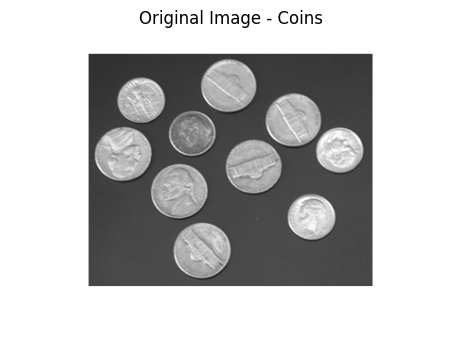

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# New image 
imgFile = 'Coins.png'

# Load the original image
img = cv2.imread(imgFile)

# Convert to Grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Apply Gaussian Blur to reduce noise
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Display the original image
plt.figure(figsize=(6, 4))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image - Coins')
plt.axis('off')
plt.show()

### **1.1 Sobel Edge Detector**


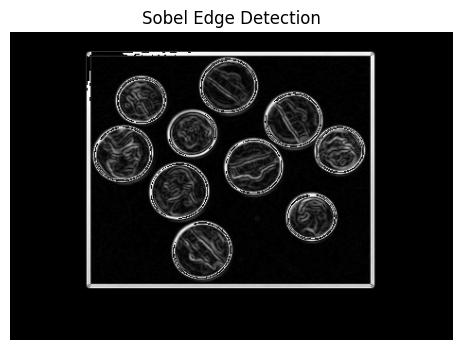

In [15]:
# Sobel Edge Detection
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_final = np.uint8(np.absolute(sobel_combined))

plt.figure(figsize=(6, 4))
plt.imshow(sobel_final, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('off')
plt.show()

### **1.2 Prewitt Edge Detector**


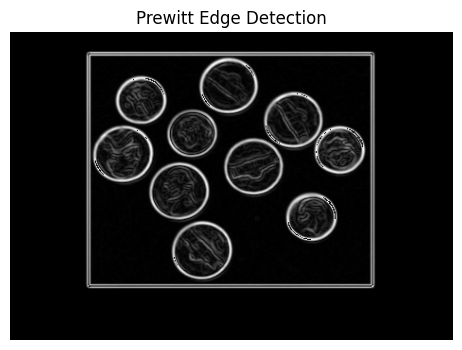

In [17]:
# Define Prewitt Kernels manually
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

# Apply filters
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

# Calculate Magnitude
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_final = np.uint8(np.absolute(prewitt_combined))

plt.figure(figsize=(6, 4))
plt.imshow(prewitt_final, cmap='gray')
plt.title('Prewitt Edge Detection')
plt.axis('off')
plt.show()

### **1.3 Canny Edge Detector**


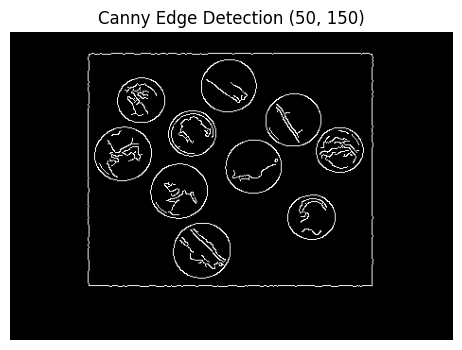

In [18]:
# Canny Edge Detection (Default thresholds: 50, 150)
canny_final = cv2.Canny(blurred, 50, 150)

plt.figure(figsize=(6, 4))
plt.imshow(canny_final, cmap='gray')
plt.title('Canny Edge Detection (50, 150)')
plt.axis('off')
plt.show()

### **1.4 Comparison of All Three Methods**


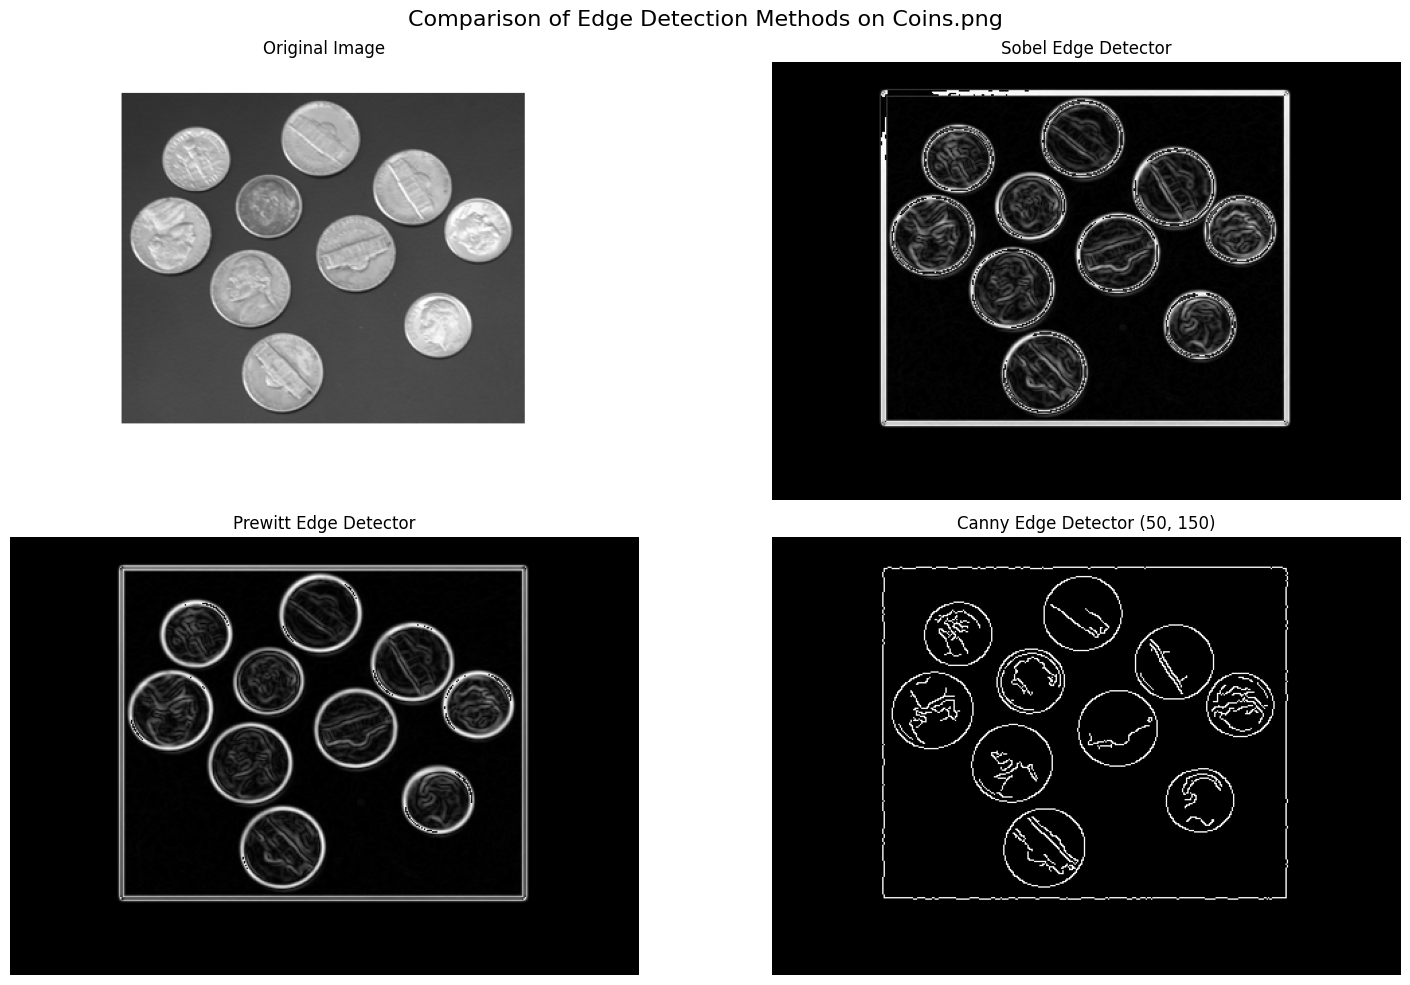

In [19]:
plt.figure(figsize=(16, 10))

# Original Image
plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

# Sobel
plt.subplot(2, 2, 2)
plt.imshow(sobel_final, cmap='gray')
plt.title('Sobel Edge Detector')
plt.axis('off')

# Prewitt
plt.subplot(2, 2, 3)
plt.imshow(prewitt_final, cmap='gray')
plt.title('Prewitt Edge Detector')
plt.axis('off')

# Canny
plt.subplot(2, 2, 4)
plt.imshow(canny_final, cmap='gray')
plt.title('Canny Edge Detector (50, 150)')
plt.axis('off')

plt.suptitle('Comparison of Edge Detection Methods on Coins.png', fontsize=16)
plt.tight_layout()
plt.show()

## **Task 2: Investigate the Effect of Canny Thresholds**

We apply Canny edge detection using three different threshold pairs:
- Low = 30, High = 90
- Low = 50, High = 150
- Low = 100, High = 200

Then, we display the three resulting edge maps side by side and explain the effects.

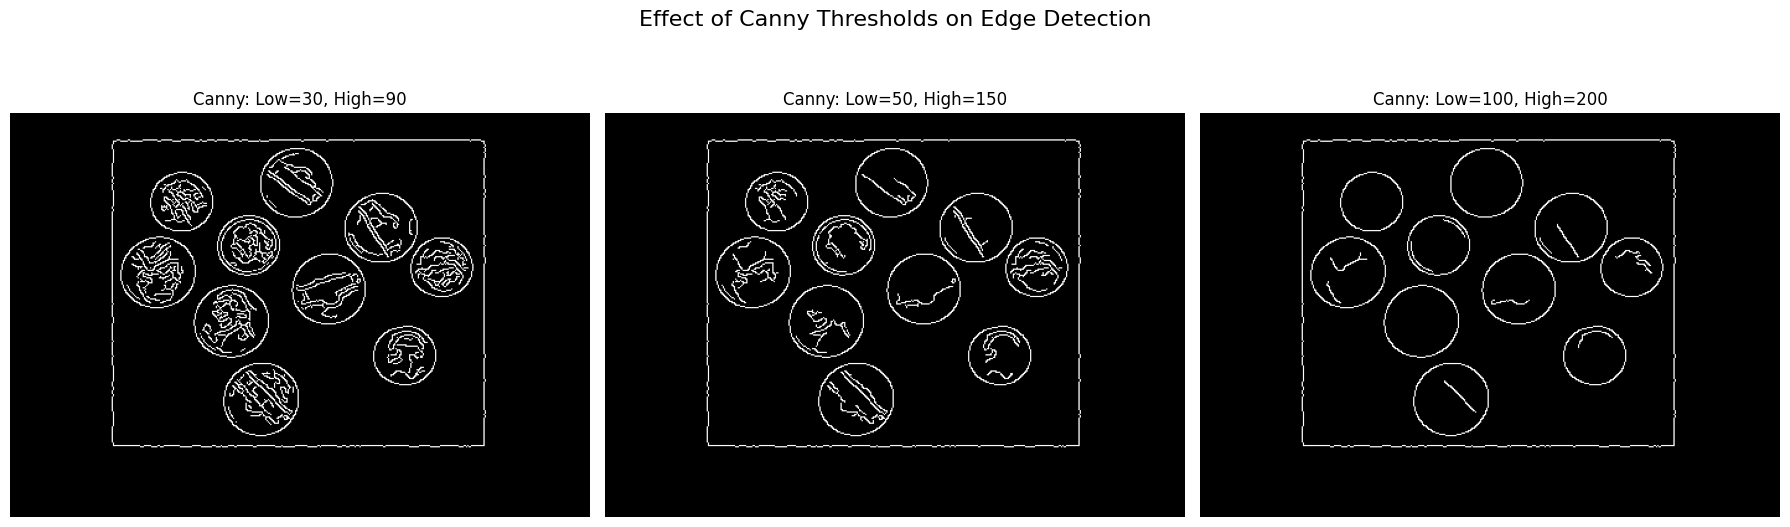

In [20]:
# Apply Canny with different threshold pairs
edges_low = cv2.Canny(blurred, 30, 90)
edges_medium = cv2.Canny(blurred, 50, 150)
edges_high = cv2.Canny(blurred, 100, 200)

# Display the three resulting edge maps side by side
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(edges_low, cmap='gray')
plt.title('Canny: Low=30, High=90')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(edges_medium, cmap='gray')
plt.title('Canny: Low=50, High=150')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(edges_high, cmap='gray')
plt.title('Canny: Low=100, High=200')
plt.axis('off')

plt.suptitle('Effect of Canny Thresholds on Edge Detection', fontsize=16)
plt.tight_layout()
plt.show()

### **Explanation of Threshold Effects**

**1. Low Thresholds (30, 90):**
- **Number of Edges:** High. The algorithm detects a large number of edges.
- **Visibility of Details:** Very high. Many fine details and textures are captured, but this also means more noise and false edges are detected.
- **Use Case:** Useful when you want to capture every possible detail, even at the cost of noise.

**2. Medium Thresholds (50, 150):**
- **Number of Edges:** Moderate. A balanced number of edges are detected.
- **Visibility of Details:** Good. Major edges are clearly visible while some noise is filtered out. This is a common default setting.
- **Use Case:** General-purpose edge detection where a balance between detail and noise is needed.

**3. High Thresholds (100, 200):**
- **Number of Edges:** Low. Only the strongest, most prominent edges are detected.
- **Visibility of Details:** Low. Fine details are lost, but the resulting edge map is very clean with minimal noise.
- **Use Case:** Useful when you only care about the main structure or outlines of objects and want to ignore texture and noise.

**Conclusion:**
As the thresholds increase, the number of detected edges decreases, and the algorithm becomes more selective, focusing only on strong edges. Lower thresholds capture more detail but also more noise.